In [1]:

!pip -q install datasets scikit-learn pandas numpy matplotlib seaborn joblib underthesea


In [2]:
import gc
import json
import re
import unicodedata
from dataclasses import asdict, dataclass, field
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from torch.optim import AdamW
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    get_linear_schedule_with_warmup,
    set_seed,
)
from underthesea import word_tokenize

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression



In [3]:
WORK_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("outputs")
@dataclass
class Config:
    seed: int = 42
    dataset_name: str = "uitnlp/vietnamese_students_feedback"
    dataset_revision: str = "refs/convert/parquet"
    text_col: str = "sentence"
    label_col: str = "sentiment"
    model_name_or_path: str | None = None
    hub_model_name: str = "vinai/phobert-base"
    max_length: int = 128
    epochs: int = 5
    train_batch_size: int = 16
    eval_batch_size: int = 32
    learning_rate: float = 2e-5
    weight_decay: float = 0.01
    warmup_ratio: float = 0.1
    max_grad_norm: float = 1.0
    early_stopping_patience: int = 2
    use_class_weights: bool = False
    use_multi_gpu: bool = True
    output_dir: Path = field(default_factory=lambda: WORK_DIR / "result/DTU-CS/HGK")
   
    @property
    def model_dir(self) -> Path:
        return self.output_dir / "best_model"

    @property
    def results_dir(self) -> Path:
        return self.output_dir / "results"


CFG = Config()

LABEL_NAMES = ["Negative", "Neutral", "Positive"]
NUM_LABELS = len(LABEL_NAMES)
ID2LABEL = dict(enumerate(LABEL_NAMES))
LABEL2ID = {name: idx for idx, name in ID2LABEL.items()}
TEXT, LABEL = CFG.text_col, CFG.label_col

CFG.model_dir.mkdir(parents=True, exist_ok=True)
CFG.results_dir.mkdir(parents=True, exist_ok=True)

set_seed(CFG.seed)  # seed random, numpy, torch (CPU + CUDA)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_GPU = torch.cuda.device_count() if CFG.use_multi_gpu else min(1, torch.cuda.device_count())
USE_AMP = device.type == "cuda"
TRAIN_BATCH_SIZE = CFG.train_batch_size * max(1, N_GPU)
EVAL_BATCH_SIZE = CFG.eval_batch_size * max(1, N_GPU)

print("Device:", device, "| GPU dùng:", N_GPU, "| AMP:", USE_AMP)
print("Batch size train/eval (tổng):", TRAIN_BATCH_SIZE, "/", EVAL_BATCH_SIZE)
print("Output:", CFG.output_dir)

def print_gpu_info() -> None:
    print("CUDA Available:", torch.cuda.is_available())
    print("PyTorch Version:", torch.__version__)
    if not torch.cuda.is_available():
        return
    print("\nSố GPU được cấp:", torch.cuda.device_count())
    for i in range(torch.cuda.device_count()):
        props = torch.cuda.get_device_properties(i)
        print(f"\n========== GPU {i} ==========")
        print("Tên GPU:", props.name)
        print(f"Tổng VRAM: {props.total_memory / 1024**3:.2f} GB")
        print(f"VRAM đang dùng: {torch.cuda.memory_allocated(i) / 1024**3:.2f} GB")
        print(f"VRAM được PyTorch giữ: {torch.cuda.memory_reserved(i) / 1024**3:.2f} GB")
        print(f"Compute Capability: {props.major}.{props.minor}")


print_gpu_info()

Device: cuda | GPU dùng: 2 | AMP: True
Batch size train/eval (tổng): 32 / 64
Output: /kaggle/working/result/DTU-CS/HGK
CUDA Available: True
PyTorch Version: 2.11.0+cu130

Số GPU được cấp: 2

========== GPU 0 ==========
Tên GPU: Tesla T4
Tổng VRAM: 14.56 GB
VRAM đang dùng: 0.00 GB
VRAM được PyTorch giữ: 0.00 GB
Compute Capability: 7.5

========== GPU 1 ==========
Tên GPU: Tesla T4
Tổng VRAM: 14.56 GB
VRAM đang dùng: 0.00 GB
VRAM được PyTorch giữ: 0.00 GB
Compute Capability: 7.5


In [4]:
raw = load_dataset(CFG.dataset_name, revision=CFG.dataset_revision)
splits = {
    name: raw[name].to_pandas()[[TEXT, LABEL]]
    for name in ["train", "validation", "test"]
}

distribution = pd.DataFrame(
    {name: df[LABEL].value_counts().sort_index() for name, df in splits.items()}
).rename(index=ID2LABEL)

display(distribution)
display((distribution / distribution.sum() * 100).round(2).add_suffix(" (%)"))
display(splits["train"].head())

default/train/0000.parquet: reconstructing file:   0%|          |  0.00B /  475kB            

default/train/0000.parquet: downloading bytes:           |  0.00B            

default/validation/0000.parquet: reconstructing file:   0%|          |  0.00B / 63.3kB            

default/validation/0000.parquet: downloading bytes:           |  0.00B            

default/test/0000.parquet: reconstructing file:   0%|          |  0.00B /  134kB            

default/test/0000.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating test split: 0 examples [00:00, ? examples/s]

,train,validation,test
sentiment,,,
Negative,5325,705,1409
Neutral,458,73,167
Positive,5643,805,1590


,train (%),validation (%),test (%)
sentiment,,,
Negative,46.60,44.54,44.50
Neutral,4.01,4.61,5.27
Positive,49.39,50.85,50.22


,sentence,sentiment
0,slide giáo trình đầy đủ .,2
1,"nhiệt tình giảng dạy , gần gũi với sinh viên .",2
2,đi học đầy đủ full điểm chuyên cần .,0
3,chưa áp dụng công nghệ thông tin và các thiết ...,0
4,"thầy giảng bài hay , có nhiều bài tập ví dụ ng...",2


In [5]:
def normalize_text(text) -> str:
    """Chuẩn hóa Unicode NFC, chữ thường, gộp khoảng trắng."""
    if pd.isna(text):
        return ""
    text = unicodedata.normalize("NFC", str(text)).lower()
    return re.sub(r"\s+", " ", text).strip()


def audit_split(df: pd.DataFrame) -> dict:
    norm = df[TEXT].map(normalize_text)
    n_labels = df.groupby(norm)[LABEL].transform("nunique")
    return {
        "samples": len(df),
        "empty_texts": int((norm == "").sum()),
        "duplicate_rows": int(norm.duplicated().sum()),
        "conflict_rows": int((n_labels > 1).sum()),
    }


display(pd.DataFrame({name: audit_split(df) for name, df in splits.items()}).T)
norm_sets = {name: set(df[TEXT].map(normalize_text)) for name, df in splits.items()}
for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    print(f"{a} ∩ {b}: {len(norm_sets[a] & norm_sets[b])}")

train_norm = splits["train"][TEXT].map(normalize_text)
conflict_mask = splits["train"].groupby(train_norm)[LABEL].transform("nunique") > 1
display(splits["train"][conflict_mask].assign(norm=train_norm).sort_values("norm"))

,samples,empty_texts,duplicate_rows,conflict_rows
train,11426,0,1,2
validation,1583,0,0,0
test,3166,0,0,0


train ∩ validation: 0
train ∩ test: 0
validation ∩ test: 0


,sentence,sentiment,norm
11293,"thầy dạy hay , tuy nhiên còn nhiều chỗ chưa th...",2,"thầy dạy hay , tuy nhiên còn nhiều chỗ chưa th..."
11417,"thầy dạy hay , tuy nhiên còn nhiều chỗ chưa th...",0,"thầy dạy hay , tuy nhiên còn nhiều chỗ chưa th..."


In [6]:
def clean_train(df: pd.DataFrame) -> pd.DataFrame:
    norm = df[TEXT].map(normalize_text)
    n_labels = df.groupby(norm)[LABEL].transform("nunique")
    keep = (norm != "") & (n_labels == 1) & ~norm.duplicated()
    return df[keep].reset_index(drop=True)


train_clean = clean_train(splits["train"])
print(f"Train: {len(splits['train'])} -> {len(train_clean)} "
      f"(loại {len(splits['train']) - len(train_clean)} mẫu)")

Train: 11426 -> 11424 (loại 2 mẫu)


In [7]:
def preprocess_text(text) -> str:
    text = normalize_text(text)
    return word_tokenize(text, format="text") if text else ""


def add_segmented_text(df: pd.DataFrame, name: str) -> pd.DataFrame:
    segmented = [preprocess_text(t) for t in tqdm(df[TEXT], desc=f"Tách từ {name}")]
    return df.assign(segmented_text=segmented)


train_df = add_segmented_text(train_clean, "train")
val_df = add_segmented_text(splits["validation"], "validation")
test_df = add_segmented_text(splits["test"], "test")

display(train_df[[TEXT, "segmented_text"]].head())

Tách từ train:   0%|          | 0/11424 [00:00<?, ?it/s]

Tách từ validation:   0%|          | 0/1583 [00:00<?, ?it/s]

Tách từ test:   0%|          | 0/3166 [00:00<?, ?it/s]

,sentence,segmented_text
0,slide giáo trình đầy đủ .,slide giáo_trình đầy_đủ .
1,"nhiệt tình giảng dạy , gần gũi với sinh viên .","nhiệt_tình giảng_dạy , gần_gũi với sinh_viên ."
2,đi học đầy đủ full điểm chuyên cần .,đi học đầy_đủ full_điểm chuyên cần .
3,chưa áp dụng công nghệ thông tin và các thiết ...,chưa áp_dụng công_nghệ_thông_tin và các thiết_...
4,"thầy giảng bài hay , có nhiều bài tập ví dụ ng...","thầy giảng bài hay , có nhiều bài_tập ví_dụ ng..."


Accuracy: 0.8875552747946936
Macro-F1: 0.7277586556058413
              precision    recall  f1-score   support

    Negative       0.88      0.94      0.91      1409
     Neutral       0.42      0.31      0.36       167
    Positive       0.94      0.90      0.92      1590

    accuracy                           0.89      3166
   macro avg       0.74      0.72      0.73      3166
weighted avg       0.88      0.89      0.88      3166



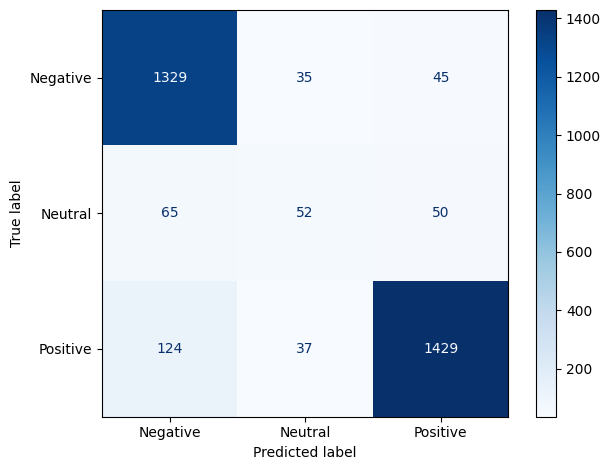

['/kaggle/working/tfidf_logreg_baseline.joblib']

In [8]:
X_train = train_df["segmented_text"].fillna("").astype(str)
X_val = val_df["segmented_text"].fillna("").astype(str)
X_test = test_df["segmented_text"].fillna("").astype(str)

y_train = train_df["sentiment"].astype(int)
y_val = val_df["sentiment"].astype(int)
y_test = test_df["sentiment"].astype(int)

baseline = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        min_df=2,
        max_features=50000,
        sublinear_tf=True,
        lowercase=False
    )),
    ("logreg", LogisticRegression(
        C=1.0,
        class_weight={0: 1, 1: 5, 2: 1},
        max_iter=2000,
        random_state=42
    ))
])
baseline.fit(X_train, y_train)
y_pred = baseline.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Macro-F1:", f1_score(
    y_test, y_pred, average="macro"
))
print(classification_report(
    y_test, y_pred,
    target_names=["Negative", "Neutral", "Positive"]
))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Negative", "Neutral", "Positive"],
    cmap="Blues"
)
plt.tight_layout()
plt.show()
joblib.dump(
    baseline,
    "/kaggle/working/tfidf_logreg_baseline.joblib"
)


In [9]:
def resolve_model_path(cfg: Config) -> str:
    if cfg.model_name_or_path:
        return cfg.model_name_or_path
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        for config_file in sorted(kaggle_input.rglob("config.json")):
            if "phobert" in str(config_file).lower():
                return str(config_file.parent)
    return cfg.hub_model_name


MODEL_PATH = resolve_model_path(CFG)
print("Model:", MODEL_PATH)

# PhoBERT chỉ có tokenizer dạng slow (BPE)
tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH, use_fast=False)

lengths = pd.Series(
    [len(ids) for ids in tokenizer(train_df["segmented_text"].tolist())["input_ids"]]
)
display(lengths.describe(percentiles=[0.5, 0.95, 0.99]).round(1).to_frame("tokens"))
print(f"Tỷ lệ bị cắt tại max_length={CFG.max_length}: "
      f"{(lengths > CFG.max_length).mean():.2%}")

Model: /kaggle/input/models/dino16/phobert-base/transformers/default/1/PhoBERT-base


,tokens
count,11424.0
mean,13.6
std,8.5
min,4.0
50%,11.0
95%,30.0
99%,46.0
max,129.0


Tỷ lệ bị cắt tại max_length=128: 0.01%


In [10]:
class SentimentDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length: int):
        self.encodings = tokenizer(list(texts), max_length=max_length, truncation=True)
        self.labels = list(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: values[idx] for key, values in self.encodings.items()}
        item["labels"] = self.labels[idx]
        return item


collator = DataCollatorWithPadding(tokenizer=tokenizer, return_tensors="pt")


def make_loader(df: pd.DataFrame, batch_size: int, shuffle: bool) -> DataLoader:
    dataset = SentimentDataset(df["segmented_text"], df[LABEL], tokenizer, CFG.max_length)
    generator = torch.Generator().manual_seed(CFG.seed) if shuffle else None
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        collate_fn=collator,
        generator=generator,
        num_workers=0,
    )


train_loader = make_loader(train_df, TRAIN_BATCH_SIZE, shuffle=True)
val_loader = make_loader(val_df, EVAL_BATCH_SIZE, shuffle=False)
test_loader = make_loader(test_df, EVAL_BATCH_SIZE, shuffle=False)

sample_batch = next(iter(train_loader))
print({key: tuple(value.shape) for key, value in sample_batch.items()})

{'input_ids': (32, 29), 'attention_mask': (32, 29), 'labels': (32,)}


In [11]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_PATH,
    num_labels=NUM_LABELS,
    id2label=ID2LABEL,
    label2id=LABEL2ID,
).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Tham số: {n_params:,}")

if N_GPU > 1:
    model = nn.DataParallel(model)
    print(f"DataParallel trên {N_GPU} GPU")


def unwrap(model):
    """Lấy model gốc (bỏ lớp DataParallel) để lưu checkpoint."""
    return model.module if isinstance(model, nn.DataParallel) else model

# Loss (tùy chọn trọng số lớp để xử lý mất cân bằng)
class_weights = None
if CFG.use_class_weights:
    counts = np.bincount(train_df[LABEL], minlength=NUM_LABELS)
    class_weights = torch.tensor(
        counts.sum() / (NUM_LABELS * counts), dtype=torch.float, device=device
    )
    print("Class weights:", class_weights.cpu().numpy().round(3))
criterion = nn.CrossEntropyLoss(weight=class_weights)

no_decay = ("bias", "LayerNorm.weight")
optimizer = AdamW(
    [
        {"params": [p for n, p in model.named_parameters() if not any(k in n for k in no_decay)],
         "weight_decay": CFG.weight_decay},
        {"params": [p for n, p in model.named_parameters() if any(k in n for k in no_decay)],
         "weight_decay": 0.0},
    ],
    lr=CFG.learning_rate,
)

total_steps = CFG.epochs * len(train_loader)
warmup_steps = int(total_steps * CFG.warmup_ratio)
scheduler = get_linear_schedule_with_warmup(optimizer, warmup_steps, total_steps)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

print(f"Steps/epoch: {len(train_loader)} | Tổng: {total_steps} | Warmup: {warmup_steps}")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: /kaggle/input/models/dino16/phobert-base/transformers/default/1/PhoBERT-base
Key                        | Status     | 
---------------------------+------------+-
pooler.dense.bias          | UNEXPECTED | 
pooler.dense.weight        | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Tham số: 135,000,579
DataParallel trên 2 GPU
Steps/epoch: 357 | Tổng: 1785 | Warmup: 178


In [12]:
def to_device(batch: dict) -> tuple[dict, torch.Tensor]:
    batch = {key: value.to(device) for key, value in batch.items()}
    labels = batch.pop("labels")
    return batch, labels


def train_one_epoch(model, loader, optimizer, scheduler, scaler, criterion, desc="") -> float:
    model.train()
    total_loss, n_samples = 0.0, 0
    progress = tqdm(loader, desc=desc, leave=False)

    for batch in progress:
        inputs, labels = to_device(batch)
        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            logits = model(**inputs).logits
        loss = criterion(logits.float(), labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.max_grad_norm)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        total_loss += loss.item() * labels.size(0)
        n_samples += labels.size(0)
        progress.set_postfix(loss=f"{total_loss / n_samples:.4f}")

    return total_loss / n_samples


@torch.inference_mode()
def evaluate(model, loader, criterion) -> dict:
    model.eval()
    total_loss = 0.0
    all_preds, all_labels = [], []

    for batch in loader:
        inputs, labels = to_device(batch)
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            logits = model(**inputs).logits
        total_loss += criterion(logits.float(), labels).item() * labels.size(0)
        all_preds.append(logits.argmax(dim=-1).cpu())
        all_labels.append(labels.cpu())

    y_pred = torch.cat(all_preds).numpy()
    y_true = torch.cat(all_labels).numpy()
    return {
        "loss": total_loss / len(y_true),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, labels=list(range(NUM_LABELS)),
                             average="macro", zero_division=0),
        "y_true": y_true,
        "y_pred": y_pred,
    }

In [13]:
history = []
best_f1, best_epoch, patience_left = -1.0, None, CFG.early_stopping_patience

for epoch in range(1, CFG.epochs + 1):
    train_loss = train_one_epoch(
        model, train_loader, optimizer, scheduler, scaler, criterion,
        desc=f"Epoch {epoch}/{CFG.epochs}",
    )
    val = evaluate(model, val_loader, criterion)
    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val["loss"],
        "val_accuracy": val["accuracy"],
        "val_macro_f1": val["macro_f1"],
    })
    print(f"Epoch {epoch}: train_loss={train_loss:.4f} | val_loss={val['loss']:.4f} | "
          f"val_acc={val['accuracy']:.4f} | val_macro_f1={val['macro_f1']:.4f}")

    if val["macro_f1"] > best_f1:
        best_f1, best_epoch = val["macro_f1"], epoch
        patience_left = CFG.early_stopping_patience
        unwrap(model).save_pretrained(CFG.model_dir)
        tokenizer.save_pretrained(CFG.model_dir)
        print("  -> Lưu checkpoint tốt nhất")
    else:
        patience_left -= 1
        if patience_left == 0:
            print("  -> Early stopping")
            break

history_df = pd.DataFrame(history)
history_df.to_csv(CFG.results_dir / "training_history.csv", index=False)
print(f"\nBest epoch: {best_epoch} | Best val Macro-F1: {best_f1:.4f}")

Epoch 1/5:   0%|          | 0/357 [00:00<?, ?it/s]

Epoch 1: train_loss=0.4320 | val_loss=0.2051 | val_acc=0.9438 | val_macro_f1=0.8307


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  -> Lưu checkpoint tốt nhất


Epoch 2/5:   0%|          | 0/357 [00:00<?, ?it/s]

Epoch 2: train_loss=0.1809 | val_loss=0.2108 | val_acc=0.9476 | val_macro_f1=0.8464


... (10 outputs left out)

Epoch 5/5:   0%|          | 0/357 [00:00<?, ?it/s]

Epoch 5: train_loss=0.0819 | val_loss=0.2162 | val_acc=0.9526 | val_macro_f1=0.8701


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  -> Lưu checkpoint tốt nhất

Best epoch: 5 | Best val Macro-F1: 0.8701


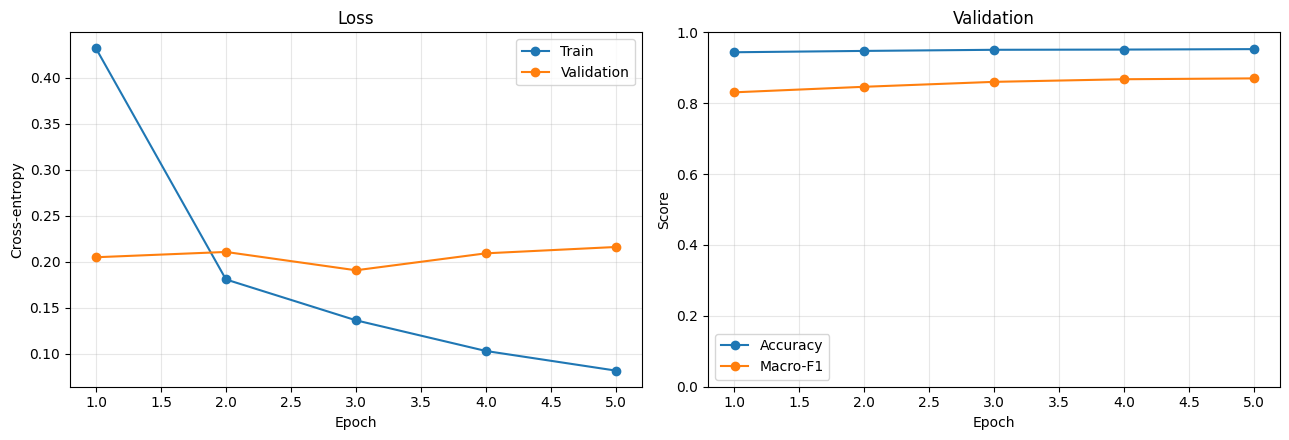

In [14]:
fig, (ax_loss, ax_score) = plt.subplots(1, 2, figsize=(13, 4.5))

ax_loss.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train")
ax_loss.plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation")
ax_loss.set(title="Loss", xlabel="Epoch", ylabel="Cross-entropy")

ax_score.plot(history_df["epoch"], history_df["val_accuracy"], marker="o", label="Accuracy")
ax_score.plot(history_df["epoch"], history_df["val_macro_f1"], marker="o", label="Macro-F1")
ax_score.set(title="Validation", xlabel="Epoch", ylabel="Score", ylim=(0, 1))

for ax in (ax_loss, ax_score):
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(CFG.results_dir / "training_curves.png", dpi=200)
plt.show()

In [15]:
del model, optimizer, scheduler
gc.collect()
torch.cuda.empty_cache()

best_model = AutoModelForSequenceClassification.from_pretrained(CFG.model_dir).to(device)
eval_model = nn.DataParallel(best_model) if N_GPU > 1 else best_model
test = evaluate(eval_model, test_loader, criterion)

print("========== PHOBERT TEST RESULTS ==========")
print(f"Accuracy: {test['accuracy']:.4f}")
print(f"Macro-F1: {test['macro_f1']:.4f}\n")
print(classification_report(
    test["y_true"], test["y_pred"],
    labels=list(range(NUM_LABELS)), target_names=LABEL_NAMES,
    digits=4, zero_division=0,
))

metrics = {
    "model": "PhoBERT-base",
    "best_epoch": best_epoch,
    "val_macro_f1": best_f1,
    "test_accuracy": test["accuracy"],
    "test_macro_f1": test["macro_f1"],
}
with open(CFG.results_dir / "test_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)
with open(CFG.results_dir / "config.json", "w", encoding="utf-8") as f:
    json.dump(asdict(CFG), f, indent=2, default=str)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

========== PHOBERT TEST RESULTS ==========
Accuracy: 0.9419
Macro-F1: 0.8380

              precision    recall  f1-score   support

    Negative     0.9519    0.9688    0.9603      1409
     Neutral     0.7368    0.5030    0.5979       167
    Positive     0.9475    0.9642    0.9557      1590

    accuracy                         0.9419      3166
   macro avg     0.8787    0.8120    0.8380      3166
weighted avg     0.9383    0.9419    0.9389      3166



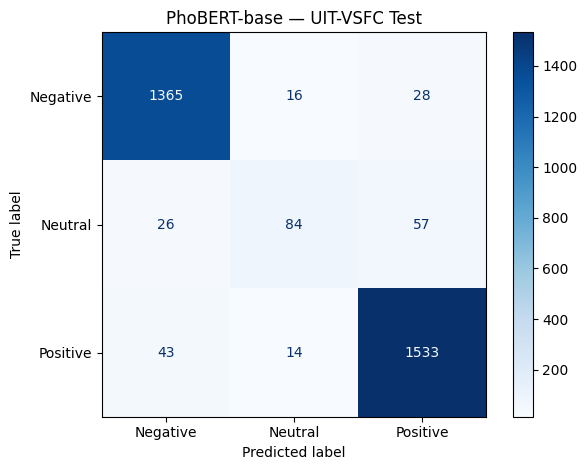

Số mẫu dự đoán sai: 184


pred_label,Negative,Neutral,Positive
true_label,,,
Negative,0,16,28
Neutral,26,0,57
Positive,43,14,0


,sentence,true_label,pred_label
6,tính điểm thi đua các nhóm .,Positive,Neutral
12,trong trường macbook thầy số hai thì không có ...,Positive,Negative
35,môn học này giúp chúng em hiểu ra những vấn đề...,Neutral,Positive
41,ổn .,Neutral,Positive
45,phần lớn chỉ là lý thuyết và bài tập .,Positive,Negative
53,như vậy tụi em sẽ định hướng tốt hơn và tập tr...,Neutral,Positive
57,đưa nhiều bài tập khó mà có lời giải cho sinh ...,Positive,Negative
121,"ví dụ phù hợp với nội dung kiến thức , hướng d...",Neutral,Positive
123,cần có nhiều giảng viên như cô dạy hơn .,Positive,Negative
138,"chia nhỏ điểm ra , mỗi buổi 1 bài lab , nộp bà...",Negative,Neutral


In [16]:
cm = confusion_matrix(test["y_true"], test["y_pred"], labels=list(range(NUM_LABELS)))
ConfusionMatrixDisplay(cm, display_labels=LABEL_NAMES).plot(cmap="Blues", values_format="d")
plt.title("PhoBERT-base — UIT-VSFC Test")
plt.tight_layout()
plt.savefig(CFG.results_dir / "confusion_matrix.png", dpi=200)
plt.show()

errors = (
    test_df.assign(prediction=test["y_pred"])
    .query(f"{LABEL} != prediction")
    .assign(
        true_label=lambda d: d[LABEL].map(ID2LABEL),
        pred_label=lambda d: d["prediction"].map(ID2LABEL),
    )
)
print("Số mẫu dự đoán sai:", len(errors))
display(pd.crosstab(errors["true_label"], errors["pred_label"]))
display(errors[[TEXT, "true_label", "pred_label"]].head(20))
errors.to_csv(CFG.results_dir / "errors.csv", index=False, encoding="utf-8-sig")

In [17]:
@torch.inference_mode()
def predict_sentiment(texts, model=best_model) -> list[dict]:
    if isinstance(texts, str):
        texts = [texts]
    model.eval()
    inputs = tokenizer(
        [preprocess_text(t) for t in texts],
        return_tensors="pt", padding=True, truncation=True, max_length=CFG.max_length,
    ).to(device)
    probs = F.softmax(model(**inputs).logits, dim=-1).cpu().numpy()

    return [
        {
            "text": text,
            "prediction": ID2LABEL[int(p.argmax())],
            "probabilities": {ID2LABEL[i]: round(float(v), 4) for i, v in enumerate(p)},
        }
        for text, p in zip(texts, probs)
    ]


examples = [
    "Giảng viên giảng bài rất dễ hiểu.",
    "Môn học quá nhàm chán và khó hiểu.",
    "Thầy giảng bình thường, không có gì đặc biệt.",
    "Thầy dạy hay nhưng không đủ thời gian giải đáp thắc mắc.",
]
display(pd.DataFrame(predict_sentiment(examples)))

,text,prediction,probabilities
0,Giảng viên giảng bài rất dễ hiểu.,Positive,"{'Negative': 0.002, 'Neutral': 0.0016, 'Positi..."
1,Môn học quá nhàm chán và khó hiểu.,Negative,"{'Negative': 0.9892, 'Neutral': 0.0019, 'Posit..."
2,"Thầy giảng bình thường, không có gì đặc biệt.",Neutral,"{'Negative': 0.0186, 'Neutral': 0.9725, 'Posit..."
3,Thầy dạy hay nhưng không đủ thời gian giải đáp...,Negative,"{'Negative': 0.9692, 'Neutral': 0.0031, 'Posit..."
